# Giải thích XGBoost

## Lấy mẫu BRFSS 2017

Lấy ngẫu nhiên 2.000 người từ BRFSS 2017, seed 42. Mẫu chưa áp trọng số khảo sát.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_dir = Path.cwd()
if not (project_dir / "src").is_dir():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))
from src.utils import check_external_inputs, explain_xgboost_pipeline, save_png

RUN_ID, SEED, SAMPLE_N = "54c463bbe9079503", 42, 2000
source_path = project_dir / "data/processed/brfss_2017.parquet"
model_path = project_dir / "models/final" / RUN_ID / "XGBoost.joblib"
metadata_path = model_path.with_suffix(".metadata.json")
threshold_path = project_dir / "results/final_development" / RUN_ID / "XGBoost/thresholds.json"
external_dir = project_dir / "results/external_validation" / RUN_ID
results_dir = project_dir / "results/explainability" / RUN_ID
figures_dir = project_dir / "results/figures/explainability" / RUN_ID
results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
external_manifest = json.loads((external_dir / "manifest.json").read_text(encoding="utf-8"))
metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
thresholds = json.loads(threshold_path.read_text(encoding="utf-8"))
assert metadata["run_id"] == RUN_ID and metadata["model"] == "XGBoost"
assert thresholds == metadata["thresholds"] == external_manifest["thresholds"]["XGBoost"]
threshold = float(thresholds["youden"])
assert np.isfinite(threshold)
prediction_path = external_dir / "brfss_2017_XGBoost_predictions.parquet"
frozen_hashes = {}
for p, expected in [
    (source_path, external_manifest["source_sha256"][str(source_path.resolve())]),
    (model_path, external_manifest["frozen_artifact_sha256"][str(model_path.resolve())]),
    (metadata_path, external_manifest["frozen_artifact_sha256"][str(metadata_path.resolve())]),
    (threshold_path, external_manifest["frozen_artifact_sha256"][str(threshold_path.resolve())]),
    (prediction_path, external_manifest["output_sha256"][str(prediction_path.resolve())]),
]:
    digest = hashlib.sha256(p.read_bytes()).hexdigest()
    assert digest == expected
    frozen_hashes[str(p)] = digest
pipeline = joblib.load(model_path)
input_cols = metadata["config"]["columns"]
assert input_cols == [
    "age", "sex", "race_ethnicity", "bmi", "smoking_status",
    "physical_activity", "heart_attack", "stroke",
]
source = pd.read_parquet(source_path)
assert len(source) == 449219 and source.index.is_unique and source.index.notna().all()
source_row_ids = source.index.to_series(index=source.index, name="source_row_id")
sample = source.assign(source_row_id=source_row_ids).sample(n=SAMPLE_N, replace=False, random_state=SEED)
sample["sample_order"] = np.arange(SAMPLE_N)
pd.testing.assert_frame_equal(sample[source.columns], source.sample(n=SAMPLE_N, replace=False, random_state=SEED))
assert sample["source_row_id"].is_unique and sample["source_row_id"].tolist() == sample.index.tolist()
X_sample = check_external_inputs(sample, input_cols, 2017)
sample.to_parquet(results_dir / "brfss_2017_sample.parquet", index=True)
sample[["sample_order", "source_row_id"]].to_csv(results_dir / "sample_ids.csv", index=False)
pd.testing.assert_frame_equal(pd.read_parquet(results_dir / "brfss_2017_sample.parquet"), sample)
display(pd.DataFrame([{
    "Nguồn": len(source), "Cỡ mẫu": len(sample),
    "Nhãn 1": int(sample["diabetes_label"].sum()),
    "BMI thiếu": int(sample["bmi"].isna().sum()), "Seed": SEED,
    "Ngưỡng Youden NHANES": threshold,
}]))


,Nguồn,Cỡ mẫu,Nhãn 1,BMI thiếu,Seed,Ngưỡng Youden NHANES
0,449219,2000,281,156,42,0.489961


## TreeSHAP và one-hot

Dùng [TreeSHAP của XGBoost](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.Booster.predict) ở thang raw margin/log-odds, với bias làm base value. Dựa vào cấu trúc transformer, cộng SHAP có dấu của 17 cột về 8 biến trên từng người rồi mới tính mean(abs(SHAP)).

In [2]:
explanation = explain_xgboost_pipeline(pipeline, X_sample)
feature_map = explanation["mapping"]
shap_transformed = explanation["shap_transformed"]
shap_grouped = explanation["shap_grouped"]
scores = explanation["scores"]
assert shap_grouped.columns.tolist() == input_cols
assert all(frame.index.equals(sample.index) for frame in [shap_transformed, shap_grouped, scores])
numeric_transformer = pipeline.named_steps["preprocessor"].named_transformers_["numeric"]
numeric_columns = dict((name, cols) for name, _, cols in pipeline.named_steps["preprocessor"].transformers_)["numeric"]
bmi_median = float(numeric_transformer.named_steps["imputer"].statistics_[list(numeric_columns).index("bmi")])
scores["prediction_youden"] = scores["probability"].ge(threshold).astype(int)
scores["bmi_missing"] = sample["bmi"].isna()
scores["bmi_after_imputation"] = explanation["transformed"].iloc[:,
    feature_map.loc[feature_map["original_feature"].eq("bmi"), "transformed_index"].item()]
assert scores.loc[scores["bmi_missing"], "bmi_after_imputation"].eq(bmi_median).all()
np.testing.assert_allclose(scores.loc[~scores["bmi_missing"], "bmi_after_imputation"],
                           sample.loc[~scores["bmi_missing"], "bmi"], rtol=0, atol=0)
saved_prediction = pd.read_parquet(prediction_path, columns=[
    "source_row_id", "diabetes_label", "probability", "prediction_youden"
]).set_index("source_row_id").loc[sample["source_row_id"]]
assert saved_prediction.index.tolist() == sample["source_row_id"].tolist()
np.testing.assert_array_equal(saved_prediction["diabetes_label"], sample["diabetes_label"])
np.testing.assert_allclose(scores["probability"], saved_prediction["probability"], rtol=0, atol=1e-7)
np.testing.assert_array_equal(scores["prediction_youden"], saved_prediction["prediction_youden"])

keys = sample[["source_row_id", "sample_order"]]
for filename, frame in [
    ("transformed_inputs.parquet", explanation["transformed"]),
    ("shap_transformed.parquet", pd.concat([scores, shap_transformed], axis=1)),
    ("shap_grouped.parquet", pd.concat([scores, shap_grouped], axis=1)),
]:
    output = pd.concat([keys, frame], axis=1)
    assert output.index.equals(sample.index) and output["source_row_id"].is_unique
    output.to_parquet(results_dir / filename, index=True)
    pd.testing.assert_frame_equal(pd.read_parquet(results_dir / filename), output)
feature_map.to_csv(results_dir / "feature_mapping.csv", index=False)
explanation["checks"].to_csv(results_dir / "additivity_checks.csv", index=False)
ranking = shap_grouped.abs().mean().rename("mean_abs_shap_log_odds").rename_axis("feature").reset_index()
ranking["n_transformed_columns"] = ranking["feature"].map(feature_map["original_feature"].value_counts())
ranking = ranking.sort_values("mean_abs_shap_log_odds", ascending=False).reset_index(drop=True)
ranking.insert(0, "rank", np.arange(1, len(ranking) + 1))
ranking.to_csv(results_dir / "shap_ranking.csv", index=False)
display(explanation["checks"])
display(ranking)


,check,max_abs_error,absolute_tolerance
0,base + transformed SHAP vs raw margin,4.896894e-06,1.000000e-05
1,base + grouped SHAP vs raw margin,4.896894e-06,1.000000e-05
2,sigmoid(raw margin) vs predict_proba,6.973839e-08,1.000000e-07


,rank,feature,mean_abs_shap_log_odds,n_transformed_columns
0,1,age,0.872157,1
1,2,bmi,0.634370,1
2,3,race_ethnicity,0.385437,4
3,4,sex,0.191807,2
4,5,physical_activity,0.160846,2
5,6,heart_attack,0.073089,2
6,7,smoking_status,0.051977,3
7,8,stroke,0.050256,2


## Đóng góp của 8 biến

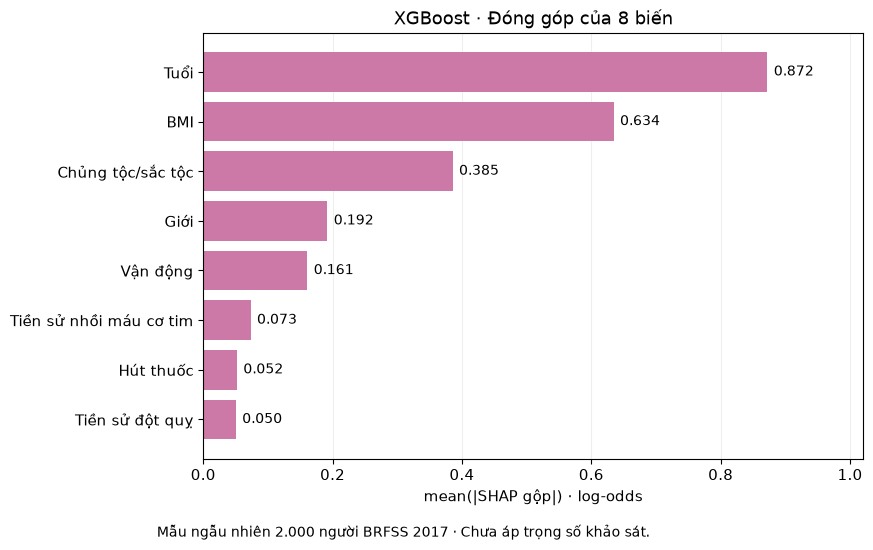

In [3]:
feature_labels = {
    "age": "Tuổi", "sex": "Giới", "race_ethnicity": "Chủng tộc/sắc tộc", "bmi": "BMI",
    "smoking_status": "Hút thuốc", "physical_activity": "Vận động",
    "heart_attack": "Tiền sử nhồi máu cơ tim", "stroke": "Tiền sử đột quỵ",
}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.titlesize": 13, "axes.labelsize": 11})
figure_paths = []
fig, ax = plt.subplots(figsize=(10, 6))
plot_rank = ranking.iloc[::-1]
ax.barh(plot_rank["feature"].map(feature_labels), plot_rank["mean_abs_shap_log_odds"], color="#CC79A7")
for position, value in enumerate(plot_rank["mean_abs_shap_log_odds"]):
    ax.text(value + 0.01, position, f"{value:.3f}", va="center", fontsize=10)
ax.set(xlabel="mean(|SHAP gộp|) · log-odds", title="XGBoost · Đóng góp của 8 biến")
ax.set_xlim(0, ranking["mean_abs_shap_log_odds"].max() * 1.17)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
fig.subplots_adjust(bottom=0.17, left=0.30, right=0.96)
fig.text(0.5, 0.04, "Mẫu ngẫu nhiên 2.000 người BRFSS 2017 · Chưa áp trọng số khảo sát.", ha="center", fontsize=10)
figure_paths.append(save_png(fig, figures_dir / "shap_importance_8_inputs.png"))
plt.show()
plt.close(fig)


## SHAP theo tuổi và BMI

Dùng tuổi và BMI gốc; BMI thiếu có ô riêng, kèm median NHANES đã dùng để impute.

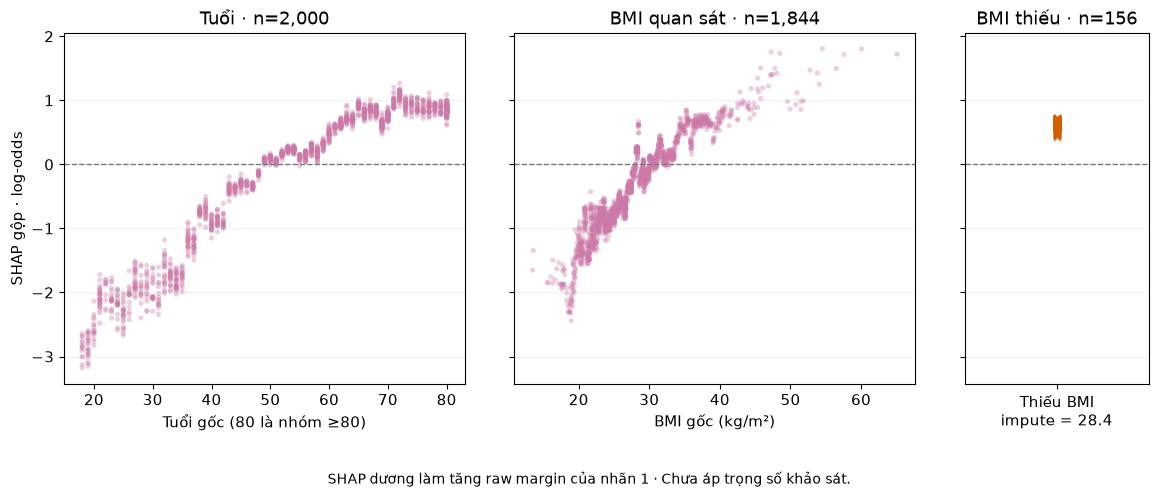

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5.4), sharey=True,
                         gridspec_kw={"width_ratios": [2.5, 2.5, 1.15]})
observed_bmi = sample["bmi"].notna()
axes[0].scatter(sample["age"], shap_grouped["age"], s=14, alpha=0.35, color="#CC79A7", edgecolors="none")
axes[0].set(title=f"Tuổi · n={len(sample):,}", xlabel="Tuổi gốc (80 là nhóm ≥80)",
            ylabel="SHAP gộp · log-odds")
axes[1].scatter(sample.loc[observed_bmi, "bmi"], shap_grouped.loc[observed_bmi, "bmi"],
                s=14, alpha=0.35, color="#CC79A7", edgecolors="none")
axes[1].set(title=f"BMI quan sát · n={int(observed_bmi.sum()):,}", xlabel="BMI gốc (kg/m²)")
axes[2].scatter(np.zeros((~observed_bmi).sum()), shap_grouped.loc[~observed_bmi, "bmi"],
                marker="x", s=25, alpha=0.55, color="#D55E00")
axes[2].set(title=f"BMI thiếu · n={int((~observed_bmi).sum()):,}",
            xticks=[0], xticklabels=[f"Thiếu BMI\nimpute = {bmi_median:g}"], xlim=(-0.5, 0.5))
for ax in axes:
    ax.axhline(0, linestyle="--", color="#777777", linewidth=1)
    ax.grid(axis="y", alpha=0.2)
fig.subplots_adjust(bottom=0.23, top=0.88, wspace=0.15)
fig.text(0.5, 0.045, "SHAP dương làm tăng raw margin của nhãn 1 · Chưa áp trọng số khảo sát.", ha="center", fontsize=10)
figure_paths.append(save_png(fig, figures_dir / "shap_age_bmi.png"))
plt.show()
plt.close(fig)


## Hai ví dụ ngẫu nhiên

Chọn ngẫu nhiên một người trong mỗi nhóm dự đoán dương/âm của mẫu, tại ngưỡng Youden cố định; nhãn thật không tham gia chọn người.

,source_row_id,sample_order,diabetes_label,probability,prediction_youden,base_value,raw_margin,sum_shap,additivity_error,case
358090,358090,1613,0,0.560424,1,0.041629,0.242884,0.201256,0.0,Dự đoán dương
404133,404133,654,0,0.434870,0,0.041629,-0.262009,-0.303638,-0.0,Dự đoán âm


,source_row_id,age,sex,race_ethnicity,bmi,smoking_status,physical_activity,heart_attack,stroke
358090,358090,0.592166,0.185060,-0.390189,0.083966,0.015939,-0.201705,-0.051683,-0.032298
404133,404133,0.058925,-0.200176,-0.466709,0.657773,-0.024731,-0.244913,-0.051123,-0.032684


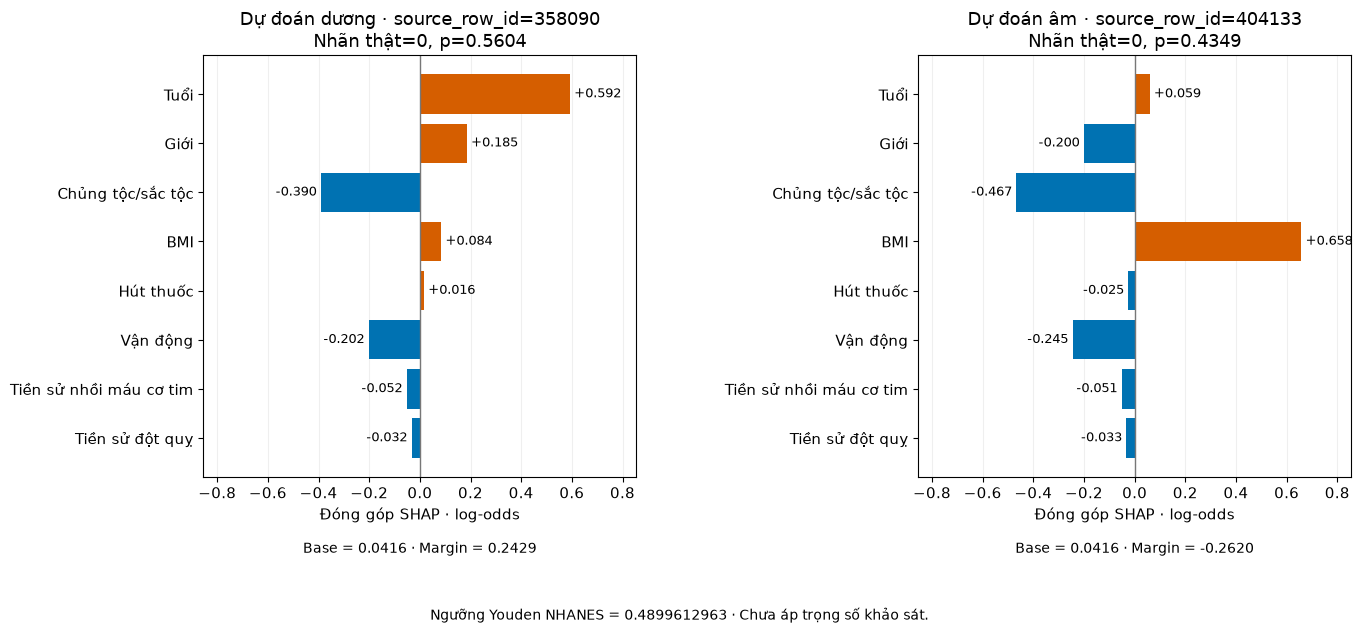

In [5]:
example_indices = []
for prediction in [1, 0]:
    candidates = scores.loc[scores["prediction_youden"].eq(prediction)]
    assert len(candidates) > 0
    example_indices.append(candidates.sample(n=1, random_state=SEED).index[0])
examples = pd.concat([
    sample.loc[example_indices, ["source_row_id", "sample_order", "diabetes_label"]],
    scores.loc[example_indices, ["probability", "prediction_youden", "base_value", "raw_margin", "sum_shap", "additivity_error"]],
], axis=1)
examples["case"] = examples["prediction_youden"].map({1: "Dự đoán dương", 0: "Dự đoán âm"})
assert examples["source_row_id"].is_unique and examples["prediction_youden"].tolist() == [1, 0]
example_contributions = shap_grouped.loc[example_indices].copy()
example_contributions.insert(0, "source_row_id", examples["source_row_id"])
examples.to_csv(results_dir / "example_choices.csv", index=False)
example_contributions.to_csv(results_dir / "example_contributions.csv", index=False)
display(examples.round(6))
display(example_contributions.round(6))
fig, axes = plt.subplots(1, 2, figsize=(14, 6.8), sharex=True)
limit = float(np.max(np.abs(shap_grouped.loc[example_indices].to_numpy()))) * 1.30
for ax, index in zip(axes, example_indices):
    row = examples.loc[index]
    values = shap_grouped.loc[index, input_cols].to_numpy()
    positions = np.arange(len(input_cols))
    ax.barh(positions, values, color=["#D55E00" if value >= 0 else "#0072B2" for value in values])
    for position, value in enumerate(values):
        ax.text(value + (limit * 0.02 if value >= 0 else -limit * 0.02), position, f"{value:+.3f}",
                ha="left" if value >= 0 else "right", va="center", fontsize=9)
    ax.set(yticks=positions, yticklabels=[feature_labels[column] for column in input_cols],
           xlim=(-limit, limit), xlabel="Đóng góp SHAP · log-odds",
           title=f"{row['case']} · source_row_id={int(row['source_row_id'])}\nNhãn thật={int(row['diabetes_label'])}, p={row['probability']:.4f}")
    ax.invert_yaxis()
    ax.axvline(0, color="#777777", linewidth=1)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)
    ax.text(0.5, -0.18, f"Base = {row['base_value']:.4f} · Margin = {row['raw_margin']:.4f}",
            transform=ax.transAxes, ha="center", fontsize=10)
fig.subplots_adjust(bottom=0.25, top=0.87, left=0.16, right=0.98, wspace=0.65)
fig.text(0.5, 0.04, f"Ngưỡng Youden NHANES = {threshold:.10f} · Chưa áp trọng số khảo sát.", ha="center", fontsize=10)
figure_paths.append(save_png(fig, figures_dir / "shap_examples.png"))
plt.show()
plt.close(fig)


## Nhận xét

Tuổi và BMI có đóng góp trung bình tuyệt đối lớn nhất trong mẫu này. SHAP giải thích đầu ra mô hình, không chứng minh nhân quả.

In [6]:
for filename, digest in frozen_hashes.items():
    assert hashlib.sha256(Path(filename).read_bytes()).hexdigest() == digest
manifest = {
    "final_run_id": RUN_ID, "model": "XGBoost", "year": 2017,
    "source_rows": len(source), "sample_n": SAMPLE_N, "seed": SEED,
    "sampling": "simple random sample without replacement from processed BRFSS 2017; pandas DataFrame.sample",
    "source_row_id": "original processed BRFSS index before sampling, reset or sorting",
    "examples": "one random observation within each predicted class in the 2000-person sample; random_state=42 independently per class",
    "threshold_youden_nhanes": threshold, "survey_weighted": False,
    "shap_method": "XGBoost Booster.predict(pred_contribs=True, approx_contribs=False); all trees",
    "method_reference": "https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.Booster.predict",
    "shap_scale": "raw margin / log-odds", "base_value": "bias column returned by pred_contribs",
    "aggregation": "signed sum over transformed columns per person, then mean absolute grouped SHAP",
    "mapping": "ColumnTransformer.transformers_, output_indices_, OneHotEncoder.categories_; no feature-name splitting",
    "input_columns": input_cols, "transformed_columns": feature_map["transformed_feature"].tolist(),
    "bmi_imputer_median_nhanes": bmi_median, "bmi_missing_n": int(sample["bmi"].isna().sum()),
    "max_additivity_error": float(explanation["checks"].iloc[1]["max_abs_error"]),
    "max_sigmoid_probability_error": float(explanation["checks"].iloc[2]["max_abs_error"]),
    "source_sha256": frozen_hashes,
    "versions": {name: importlib.metadata.version(name) for name in [
        "numpy", "pandas", "scikit-learn", "xgboost", "scipy", "joblib", "matplotlib",
    ]},
}
output_files = [p for p in results_dir.iterdir() if p.is_file() and p.name != "manifest.json"] + figure_paths
manifest["output_sha256"] = {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in output_files}
(results_dir / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame({"File": [str(p) for p in output_files]}))


,File
0,D:\NCKH Mini\diabetes-project\results\explaina...
1,D:\NCKH Mini\diabetes-project\results\explaina...
2,D:\NCKH Mini\diabetes-project\results\explaina...
3,D:\NCKH Mini\diabetes-project\results\explaina...
4,D:\NCKH Mini\diabetes-project\results\explaina...
5,D:\NCKH Mini\diabetes-project\results\explaina...
6,D:\NCKH Mini\diabetes-project\results\explaina...
7,D:\NCKH Mini\diabetes-project\results\explaina...
8,D:\NCKH Mini\diabetes-project\results\explaina...
9,D:\NCKH Mini\diabetes-project\results\explaina...
